# Прибыль карманов и карта срезов

Историческая проверка концентрации прибыли и фиксированная карта без подбора новых порогов. Полная раскладка по дням, турнирам и исходам находится в соседних JSON и Markdown.

ROI по условному флету 1 единица. История и фон разделены. Повторные входы новой версии не заполняются задним числом.

## Источники и метод

Данные: pocket-audit-results.json. Внутри сохранены SHA256 исходников и коммит. Для полного пересчёта выполнить `python3 research/selection-lab-20261018/pocket_audit.py` из корня репозитория. Вырезаем лучший день по чистой прибыли либо три наибольших результата, затем пересчитываем знаменатель. Это проверка концентрации, не тест статистической значимости.

In [1]:
from pathlib import Path
import json,io
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
base=Path.cwd()
if not (base/'pocket-audit-results.json').exists(): base=base/'research/selection-lab-20261018'
data=json.loads((base/'pocket-audit-results.json').read_text())
print('Исходный коммит:',data['source_revision'])
print('Последний снимок UTC:',data['latest_snapshot_utc'])
print('Независимых арифметических сверок:',data['quality']['independent_decimal_checks'])


Исходный коммит: 2ad15b5cb56b6caa379961c9ccf854703194ee5b
Последний снимок UTC: 2026-10-20T10:11:45.029644+00:00
Независимых арифметических сверок: 1546


## Концентрация исторической прибыли

История 13–18 октября. Показаны также минусовые результаты после удаления лучшего дня. N меняется после удаления.

Створы: N=164, ROI=11.7%; без лучшего дня N=122, ROI=9.2%; без top3 N=161, ROI=9.9%
46–60 мин: N=103, ROI=8.9%; без лучшего дня N=88, ROI=4.9%; без top3 N=100, ROI=6.0%
Один гол: N=114, ROI=8.2%; без лучшего дня N=101, ROI=5.7%; без top3 N=111, ROI=5.6%
Целая линия: N=103, ROI=6.7%; без лучшего дня N=79, ROI=-6.3%; без top3 N=100, ROI=3.8%
Опасные <1: N=129, ROI=4.2%; без лучшего дня N=111, ROI=1.4%; без top3 N=126, ROI=1.8%
Нужно ≤2: N=138, ROI=4.9%; без лучшего дня N=110, ROI=2.9%; без top3 N=135, ROI=2.6%


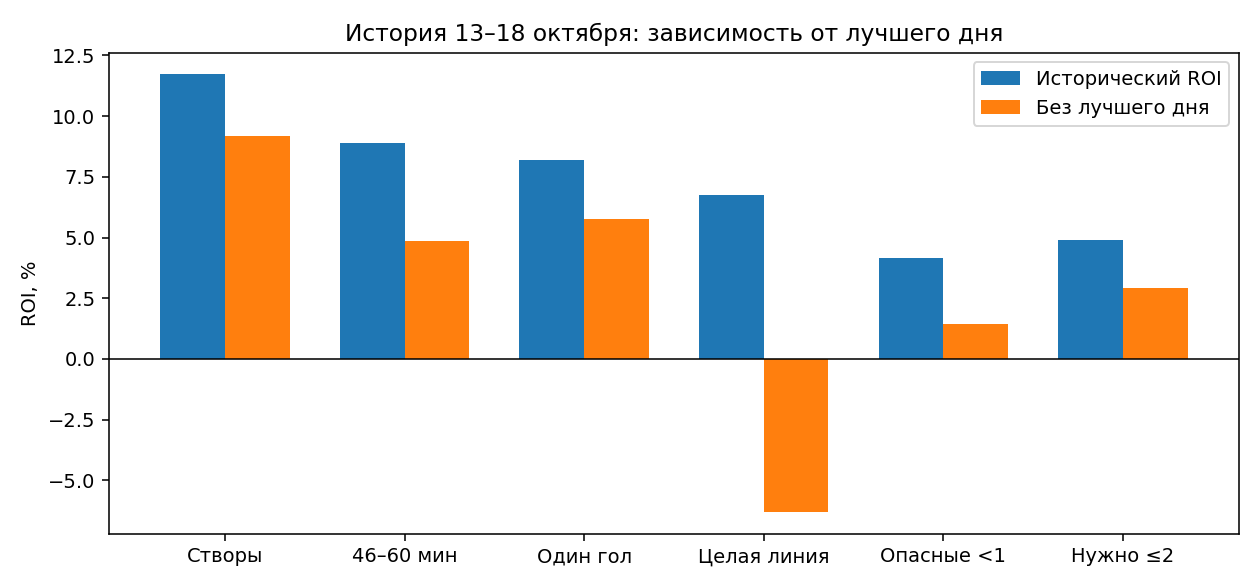

In [2]:
keys=['provider_main_sot_rate_010_020','provider_main_minute_46_60','provider_main_score_one','provider_main_integer_line','provider_main_danger_rate_lt1','provider_main_need_le2']
labels=['Створы','46–60 мин','Один гол','Целая линия','Опасные <1','Нужно ≤2']
fig,ax=plt.subplots(figsize=(9,4.2))
x=list(range(len(keys)))
ax.bar([i-.18 for i in x],[data['historical'][k]['total']['roi']*100 for k in keys],width=.36,label='Исторический ROI')
ax.bar([i+.18 for i in x],[data['historical'][k]['without_best_day']['roi']*100 for k in keys],width=.36,label='Без лучшего дня')
ax.axhline(0,color='black',linewidth=.8)
ax.set_xticks(x,labels);ax.set_ylabel('ROI, %');ax.set_title('История 13–18 октября: зависимость от лучшего дня')
ax.legend();fig.tight_layout()
image=io.BytesIO();fig.savefig(image,format='png',dpi=140);figure_bytes=image.getvalue();(base/'Проверка прибыли.png').write_bytes(figure_bytes);plt.close(fig)
for label,k in zip(labels,keys):
 v=data['historical'][k]
 print(f"{label}: N={v['total']['n']}, ROI={v['total']['roi']:.1%}; без лучшего дня N={v['without_best_day']['n']}, ROI={v['without_best_day']['roi']:.1%}; без top3 N={v['without_top3']['n']}, ROI={v['without_top3']['roi']:.1%}")


## Карта срезов

Регион × минута × нужные голы × темп створов. Полная сетка включает пустые ячейки. Ниже компактная проверка размеров и сумм. Широкий фон использует первое свежее обогащённое наблюдение с точной ценой в 5–89, а не все сырые строки и не только сильные выборы.

In [3]:
for name,g in data['slice_maps'].items():
 print(name,': ячеек',len(g['cells']),'; непустых',g['nonempty_cells'],'; пустых',g['empty_cells'],'; рассчитано',sum(r[5]for r in g['cells']))
 assert all(r[7]is None for r in g['cells']if r[5]==0)
 print('Наиболее наполненные ячейки:')
 for r in sorted(g['cells'],key=lambda r:-r[5])[:4]:print(r[:6], 'ROI='+format(r[7],'.1%')if r[7]is not None else 'ROI неизвестен')


historical_all : ячеек 864 ; непустых 114 ; пустых 750 ; рассчитано 401
Наиболее наполненные ячейки:
['Европа', '15–29', '3', '0,1–0,2', 20, 20] ROI=22.2%
['Европа', '30–45', '3', '0,1–0,2', 17, 17] ROI=19.5%
['Европа', '46–60', '≤2', '0,1–0,2', 17, 17] ROI=20.6%
['Европа', '46–60', '≤2', '<0,1', 16, 16] ROI=-13.3%
current_broad_first_priced : ячеек 864 ; непустых 77 ; пустых 787 ; рассчитано 319
Наиболее наполненные ячейки:
['Америка', '5–14', '3', '<0,1', 26, 26] ROI=-12.9%
['Европа', '5–14', '≥4', '<0,1', 24, 23] ROI=-42.0%
['Америка', '15–29', '3', '<0,1', 22, 22] ROI=-4.8%
['Западная Азия и Северная Африка', '5–14', '3', '<0,1', 22, 21] ROI=-4.0%


## Вывод

Темп створов сохраняет исторический плюс после удаления лучшего дня и трёх лучших исходов. Целая линия без лучшего дня уходит в минус. Это различие концентрации, а не подтверждение будущей доходности. Текущие проспективные данные короткие и имеют иной состав. Неизвестные регионы сохранены. Правила моделей не изменены.